# Representative spectral states from an arbitrary spectrogram, $S$, unsupervised

In [1]:
# ======================================================================
# REPRESENTATIVE ACOUSTIC STATES (RAS)
# ======================================================================

# ----------------------------------------------------------------------
# EXTERNAL DEPENDENCIES
# ----------------------------------------------------------------------
import cmocean
from collections import deque
import glob
from itertools import cycle
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import os
import pandas as pd
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.linalg import null_space
from scipy.ndimage import gaussian_filter1d, grey_opening
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.spatial.distance import pdist, squareform
from scipy.special import softmax
from sklearn.decomposition import PCA
import sys
import time
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import umap

# ----------------------------------------------------------------------
# LOCAL REPOSITORIES
# ----------------------------------------------------------------------
repo_dir = r"C:\Users\DBetchkal\PythonScripts\GITHUB"
# ----------------------------------------------------------------------
sys.path.append(os.path.join(repo_dir, "iyore"))
sys.path.append(os.path.join(repo_dir, "NPS-ActiveSpace"))
sys.path.append(os.path.join(repo_dir, "STSW"))
import iyore
from nps_active_space.utils.models import Nvspl, Srcid
from methods import stswd, wd

from sound_geometry import * 
# __all__ = [
#     "aggregate_pith_occupancy",
#     "assign_prototypes",
#     "closest_prototype",
#     "closest_row_euclidean",
#     "compute_exposure",
#     "entropy_per_row",
#     "event_plotter",
#     "family_nodes",
#     "furthest_observed_spectrum",
#     "furthest_prototype",
#     "normalize_rows",
#     "normalize_vector",
#     "pith_geometry",
#     "pith_layers",
#     "prototype_indices",
#     "prototype_runs",
#     "prototype_temporal_dynamics",
#     "run_stsw",
#     "sphere_log_map",
#     "spherical_medoid",
#     "stratified_entropy_sample",
#     "tangent_basis",
#     "tree_diameter_graph",
#     "tree_diameter_path",
#     "weighted_pca",
# ]

def ordered_path_edges(G):
    if len(G) == 0:
        return []

    # A nontrivial undirected path has exactly two endpoints.
    endpoints = [node for node, degree in G.degree if degree == 1]

    if len(endpoints) != 2:
        raise ValueError("G must be a single undirected path")

    current = endpoints[0]
    previous = None
    ordered_edges = []

    while True:
        neighbors = [
            neighbor for neighbor in G.neighbors(current)
            if neighbor != previous
        ]

        if not neighbors:
            break

        next_node = neighbors[0]
        ordered_edges.append((current, next_node))
        previous, current = current, next_node

    return ordered_edges
    
def ordered_path_nodes(G):
    edges = ordered_path_edges(G)

    if not edges:
        return list(G.nodes)

    return [edges[0][0]] + [v for _, v in edges]

def contrast_1d(a, b):

    '''
    Compute the spectral contrast angle, θ
    between two k-vectors, a and b.

    θ measures the magnitude of the smallest bivector
    which rotates a onto b in a k-dimensional vector space.
    
    Wan, K.X., Vidavsky, I. and Gross, M.L., 2002. Comparing similar spectra: from similarity index to spectral contrast angle. 
    Journal of the American Society for Mass Spectrometry, 13(1), pp.85-88. https://doi.org/10.1016/S1044-0305(01)00327-0

    Parameters
    ----------
    a: array-like float
    b: array-like float
    '''
    
    costh = np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))
    theta = np.rad2deg(np.arccos(costh))
    
    return theta

def binary_audibility_time_series(src, resolution='1s'):

    '''
    

    Parameters
    ----------

    src: 
    resolution:  

    Returns
    -------
    '''

    I_n = src.index + src.len # our noise intervals: the index and the series
    
    start_time = I_n.index.min() # the index of `I_n` is the time audibility begins
    end_time = I_n.max() # the 
    
    # Generate a time range with the desired resolution (e.g., 'T' for minute, 'S' for second)
    time_index = pd.date_range(start=start_time, end=end_time, freq=resolution)
    
    # Initialize a binary series with zeros
    binary_series = pd.Series(0, index=time_index, name="Audible")
    
    # Loop through each interval and set presence to 1 in the binary series
    for start, end in zip(I_n.index, I_n.values):
        binary_series.loc[start:end] = 1

    return binary_series

def join_src_to_nvspl(nv, src):
    '''
    '''

    boolean_sum = binary_audibility_time_series(src, resolution='1s')

    nv_aud = nv.join(boolean_sum, how="outer")
    nv_aud["Audible"].fillna(0, inplace=True)

    return nv_aud

def audibility_sir(family, overall_ta):
    """
    Observed-to-expected audibility ratio for a RAS family.

    observed:
        Number of audible spectra in the family.

    expected:
        Number of audible spectra expected if the family had
        the overall audibility rate.

    SIR:
        1 means observed audibility equals expected audibility.
        >1 means greater audibility than expected.
        <1 means lower audibility than expected.
    """
    audible = family["Audible"].dropna()

    n_i = audible.shape[0]
    observed_i = audible.sum()
    expected_i = n_i * overall_ta

    return observed_i / expected_i if expected_i > 0 else np.nan

Now processing LACLCRES2023...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1057/1057 [00:38<00:00, 27.15NVSPL files/s]


Apply greyscale opening...
Apply Gaussian high-pass filter...
Select frequency band...
Using 33 frequency bands from 12.5 to 20000 Hz.
Normalize to hypersphere...
Entropy-stratified sampling...


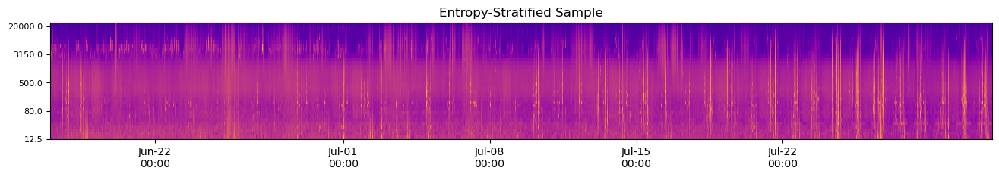

Learning Sliced-Tree Spherical Wasserstein (STSW) prototypes, X_N...


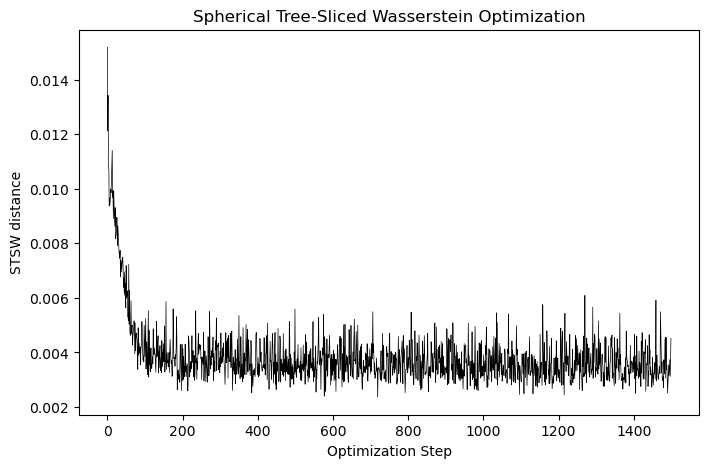

Calculating contrast with spherical medoid...

Spherical medoid
----------------
Medoid index: 247
Dimension: 33
Calculating standard percentile spectra and mapping to STSW prototype...


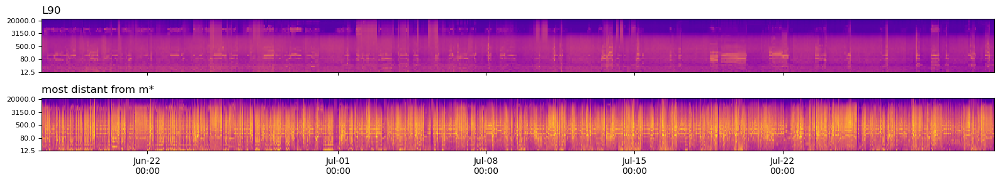

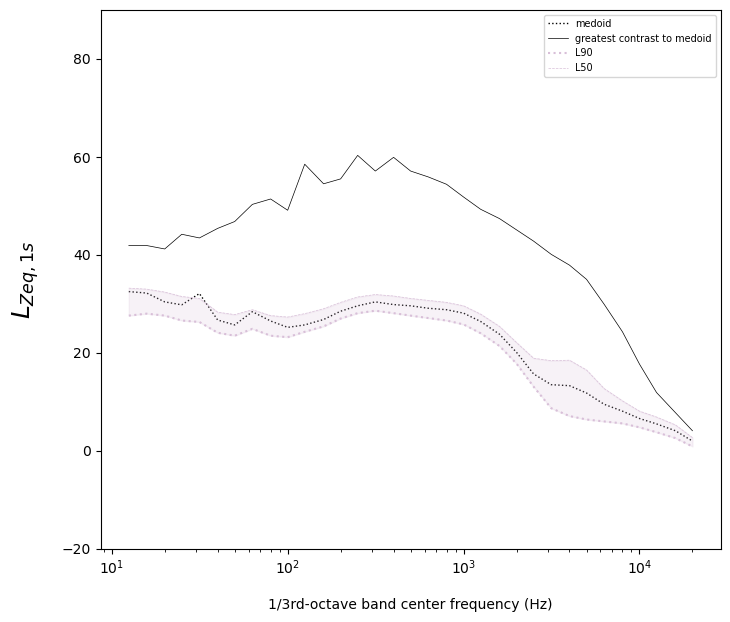

Computing tangent space $\top$ wrt to medoid...

Log-map check
-------------
Maximum | ||log_m(n)|| - d(m,n) |: 3.1086244689504383e-15

Tangent space
-------------
Original dimension: 33
Tangent dimension: 32

Weighted tangent PCA
--------------------
PC1 explained variance: 0.30727330701748373
PC2 explained variance: 0.14334186999386378
PC1 + PC2: 0.4506151770113475


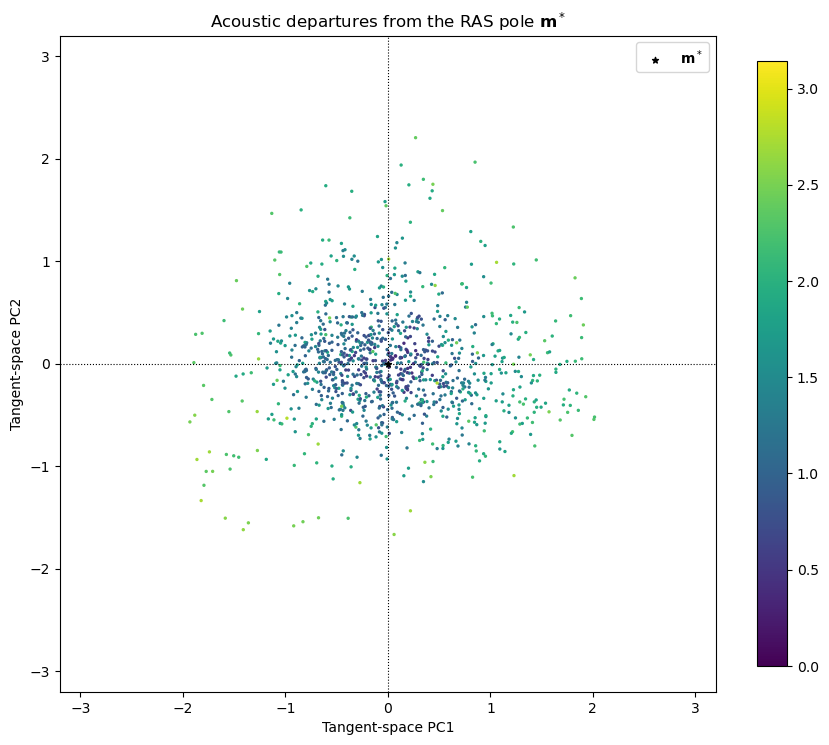


Distance from RAS
-----------------
Minimum: 0.0,  0.0°
Median: 1.38,  79.1°
Mean: 1.41,  81.0°
Maximum: 2.79,  159.8°

Farthest state
--------------
Index: 760
Geodesic distance: 2.788638284724878


In [13]:
# --------------------------------------------------------------
# LOAD DATA
# --------------------------------------------------------------

archive = iyore.Dataset(r"F:\Sound Data")
f_lower, f_upper = "12.5", "20000"

u,s,y = "LACL","CRES",2023 # really nice medoid/ecc spectra, gorgeous G_MST, but SIR results partly 'fail'



out_spectra = []

e = [e for e in archive.dataDir(unit=u, site=s, year=y)][0]

print(f"Now processing {u}{s}{y}...")

# ============================================================
# REPRESENTATIVE ACOUSTIC STATES
#
# Inputs:
#   S     : original measured spectra
#   M_df  : hyperspherical spectral-state coordinates
#   X_N   : STSW prototypes
#
# Outputs:
#  Goodness, this is ill-defined...
# ============================================================



nv_files = [e.path for e in archive.nvspl(unit=e.unit, site=e.site, year=e.year)] # available data for deployment
nv_files = np.sort(nv_files)
nv = Nvspl(nv_files[:]) # let's attempt to analyze 25 day samples... but we'll take anything we can get up to that
                             # TODO: ensure a consecutive, 25-day sample is available
if not np.isnan(nv["WindSpeed"]).all():
    nv = nv.loc[nv["WindSpeed"] <= 5.0, :] # standard procedure to remove pseudonoise artifacts
S = nv.loc[:, "12.5":"20000"].copy()

# --------------------------------------------------------------
# EXPOSURE SPACE
# --------------------------------------------------------------
# 4*60*60 works well for GLBA
# 5 minutes for aircraft, 30 minutes for vessels? 45*60 
S_E, S_O, M_df = compute_exposure(S, f_lower=f_lower, f_upper=f_upper, epsilon_t=30*60) 

# --------------------------------------------------------------
# ENTROPY-STRATIFIED SAMPLE
# --------------------------------------------------------------

print("Entropy-stratified sampling...")

sampled = stratified_entropy_sample(M_df,
                                    N=604800, # seconds = 7 days
                                    n_bins=800,
                                    random_state=679)

fig, ax = plt.subplots(1, 1, figsize=(16, 2))
event_plotter(S.loc[sampled.index], ax)
plt.title("Entropy-Stratified Sample")
plt.show()

# --------------------------------------------------------------
# RUN STSW (Sliced-Tree Spherical Wasserstein distance)
# --------------------------------------------------------------

print("Learning Sliced-Tree Spherical Wasserstein (STSW) prototypes, X_N...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Xt = torch.tensor(sampled.values, dtype=torch.float32)

# these roughly parameterized by reasoning and some trial-and-error
X_N, loss_history = run_stsw(Xt,
                             n_components=128,
                             n_steps=1500,
                             batch_size=1024, # number of prototypes: we need this to be large because we want to be sure to distinguish as much as possible - merging is possible by MST later
                             lr=5e-3,
                             ntrees=400,
                             nlines=30,
                             device=device)

plt.figure(figsize=(8, 5))
plt.plot(loss_history, color="k", lw=0.5)
plt.xlabel("Optimization Step")
plt.ylabel("STSW distance")
plt.title("Spherical Tree-Sliced Wasserstein Optimization")
plt.show()

# --------------------------------------------------------------
# SAVE
# --------------------------------------------------------------

#np.save("X_N.npy", X_N)

# print("\nSaved learned spherical representatives:")
# print("X_N.npy")

# --------------------------------------------------------------
# TEMPORAL TRAJECTORY OF PROTOTYPES
#
#
# The resulting activation weights represent empirical occupancy 
# of spherical Voronoi cells.
# --------------------------------------------------------------

prototype_assignment = assign_prototypes(M_df.values,
                                         X_N,
                                         chunk_size=100_000)

mean_activity = (np.bincount(prototype_assignment, 
                             minlength=X_N.shape[0]).astype(np.float64))

w = mean_activity.copy()
w = np.asarray(w, dtype=float)
w = w / w.sum()

# -------------------------------------------------------------
# OCCUPANCY-WEIGHTED SPHERICAL MEDOID
#
# Select the prototype having minimum expected angular distance to
# the empirical distribution of occupied acoustic states.
# -------------------------------------------------------------

print("Calculating contrast with spherical medoid...")

X = normalize_rows(X_N)

m_star, medoid_idx = spherical_medoid(X, w)
medoid_contrast_idx = furthest_prototype(X_N[medoid_idx], X_N)

print("\nSpherical medoid")
print("----------------")
print("Medoid index:", medoid_idx)
print("Dimension:", len(m_star))

# --------------------------------------------------------------
# CLASSICAL SPECTRAL REFERENCE STATES
#
# Column-wise L90, L50, and L10 spectra are calculated from the
# original measured spectra. Because these quantile spectra are not
# necessarily observed frames, each is associated with its nearest
# observed spectral realization.
# --------------------------------------------------------------

print("Calculating standard percentile spectra and mapping to STSW prototype...")

S_band = S.loc[:, f_lower:f_upper]

L90 = S_band.quantile(0.10, axis=0)
L50 = S_band.quantile(0.50, axis=0)
L10 = S_band.quantile(0.90, axis=0)

L90_idx_closest = closest_row_euclidean(S_band, L90)
L50_idx_closest = closest_row_euclidean(S_band, L50)
L10_idx_closest = closest_row_euclidean(S_band, L10)

# --------------------------------------------------------------
# MAP CLASSICAL STATES TO STSW PROTOTYPES
#
# The corresponding observed frames are already represented in M.
# Each is assigned to its nearest prototype on the hypersphere.
# --------------------------------------------------------------

v_90 = closest_prototype(M_df.iloc[L90_idx_closest].values, X_N)
v_50 = closest_prototype(M_df.iloc[L50_idx_closest].values, X_N)
v_10 = closest_prototype(M_df.iloc[L10_idx_closest].values, X_N)

idx_90 = prototype_indices(prototype_assignment, v_90)
idx_m  = prototype_indices(prototype_assignment, medoid_idx)
idx_far = prototype_indices(prototype_assignment, medoid_contrast_idx)

voronoi_L90 = S.iloc[idx_90]
voronoi_m = S.iloc[idx_m]
voronoi_m_far = S.iloc[idx_far]

medoid_spectrum = voronoi_m.quantile(0.5, axis=0)
medoid_contrast_spectrum = voronoi_m_far.quantile(0.5, axis=0)

out_spectra.append([L90.values, L50.values, medoid_spectrum.values, medoid_contrast_spectrum.values])

if((voronoi_L90.shape[0] > 0)&(voronoi_m_far.shape[0] > 0)):

    fig,ax = plt.subplots(2,1, figsize=(16,3), sharex=True)
    event_plotter(voronoi_L90, ax=ax[0])
    event_plotter(voronoi_m_far, ax=ax[1])
    ax[0].set_title("L90", loc="left")
    ax[1].set_title("most distant from m*", loc="left")
    plt.tight_layout()
    # plt.savefig(r"C:\Users\DBetchkal\LIME\test_2026_08_26"+os.sep+e.unit+e.site+str(e.year)+"_voronoi_spectrogram_comparison.png",
    #             dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    
    f_plot = M_df.columns.astype('float')
    
    plt.figure(figsize=(8,7))
    # plt.plot(S.columns.astype('float'), voronoi_L90.quantile(0.5, axis=0), color="k", ls=":")
    plt.plot(f_plot, medoid_spectrum.loc[f_lower:f_upper], color="k", ls=":", lw=1, zorder=-50, label="medoid")
    plt.plot(f_plot, medoid_contrast_spectrum.loc[f_lower:f_upper], color="k", ls="-", lw=0.5, label="greatest contrast to medoid")
    plt.plot(f_plot, L90.loc[f_lower:f_upper].values, color="thistle", ls=":", zorder=100, label="L90")
    plt.plot(f_plot, L50.loc[f_lower:f_upper].values, color="thistle", ls="--", lw=0.5, zorder=100, label="L50")
    plt.fill_between(f_plot, L90.loc[f_lower:f_upper].values, L50.loc[f_lower:f_upper].values, color="thistle", alpha=0.2)
    plt.legend(fontsize=7)
    plt.xscale('log')
    plt.ylim([-20,90])
    plt.xlabel("1/3rd-octave band center frequency (Hz)", labelpad=15)
    plt.ylabel("$L_{Zeq,1s}$", fontsize=18, labelpad=15)
    # plt.title(u+s+str(y), loc="left", fontsize=8)
    # plt.savefig(r"C:\Users\DBetchkal\LIME\test_2026_08_26"+os.sep+e.unit+e.site+str(e.year)+"_spectrum_plot.png",
    #             dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()


# ============================================================
# Compute Riemannian log map
# ============================================================

print(r"Computing tangent space $\top$ wrt to medoid...")

V, theta = sphere_log_map(X, m_star)

print("\nLog-map check")
print("-------------")

print("Maximum | ||log_m(n)|| - d(m,n) |:",
     np.max(np.abs(np.linalg.norm(V, axis=1) - theta)))

# ============================================================
# Construct tangent-space coordinate system
# ============================================================

E = tangent_basis(m_star)

# V is N × D
# E is D × (D-1)
#
# Therefore:
#
# Z = V E
#
# gives coordinates in the tangent basis.

Z = V @ E

print("\nTangent space")
print("-------------")
print("Original dimension:", X.shape[1])
print("Tangent dimension:", Z.shape[1])

# ============================================================
# Occupancy-weighted PCA
# ============================================================

Z2, components, eigvals, tangent_mean = weighted_pca(Z, w, n_components=2)

explained = eigvals / eigvals.sum()

# PC1 is the direction in tangent space along which
# the spectral departures from m^* have the greatest variance.
# PC2 is the orthogonal direction with the next greatest variance.
print("\nWeighted tangent PCA")
print("--------------------")
print("PC1 explained variance:", explained[0])
print("PC2 explained variance:", explained[1])
print("PC1 + PC2:", explained[:2].sum())

# ============================================================
# Useful quantities for every state
# ============================================================

Z2_pole = Z @ components

# Geodesic distance from RAS
rho = theta

# Tangent-space vector
log_m_n = V

# Tangent-space direction
log_norm = np.linalg.norm(V, axis=1)

direction = np.zeros_like(V)

mask = log_norm > 1e-12

direction[mask] = (V[mask] / log_norm[mask, None])

# ============================================================
# Alternative: force m* to be exactly at (0, 0)
# ============================================================
#
# This is probably the visualization I would use for the
# conceptual figure in your paper.
#
# Instead of centering PCA around the weighted tangent mean,
# simply project the tangent vectors onto the PCA directions.
#
# The log map itself guarantees:
#
#     log_m*(m*) = 0
#
# so the medoid is exactly the origin.
# ============================================================

# PCA directions from the weighted covariance
# are already stored in `components`.

fig,ax = plt.subplots(1,1, figsize=(9,8))

im = ax.scatter(Z2_pole[:, 0], Z2_pole[:, 1],
    s=2, alpha=1.0, c=rho, cmap="viridis")

# Data-defined pole
ax.scatter(0, 0, s=20, marker="*", color="k", label=r"$\mathbf{m}^*$")

ax.set_xlim([-3.2,3.2])
ax.set_ylim([-3.2,3.2])
ax.axhline(0, linewidth=0.8, color="k", ls=":")
ax.axvline(0, linewidth=0.8, color="k", ls=":")
ax.set_xlabel("Tangent-space PC1")
ax.set_ylabel("Tangent-space PC2")
ax.set_aspect(1.0)

ax.set_title(r"Acoustic departures from the RAS pole $\mathbf{m}^*$")
ax.legend()

cbar = plt.colorbar(im, shrink=0.8)
im.set_clim(vmin=0, vmax=np.pi)
plt.tight_layout()
plt.show()

# ============================================================
# Print some summary statistics
# ============================================================

print("\nDistance from RAS")
print("-----------------")
print(f"Minimum: {np.round(np.min(rho),2)},  {np.round(np.rad2deg(np.min(rho)),1)}°")
print(f"Median: {np.round(np.median(rho),2)},  {np.round(np.rad2deg(np.median(rho)),1)}°")
print(f"Mean: {np.round(np.mean(rho),2)},  {np.round(np.rad2deg(np.mean(rho)),1)}°")
print(f"Maximum: {np.round(np.max(rho),2)},  {np.round(np.rad2deg(np.max(rho)),1)}°")

# ============================================================
# Optional: identify the farthest state from the RAS
# ============================================================

far_idx = np.argmax(rho)

print("\nFarthest state")
print("--------------")
print("Index:", far_idx)
print("Geodesic distance:", rho[far_idx])

# ============================================================
# MORPHOLOGICAL MINIMUM SPANNING TREE
#
# The representative acoustic states X_N are vertices on the
# hypersphere. Pairwise geodesic separation defines the edge
# metric, and the minimum spanning tree provides a sparse
# approximation to the morphology of the representative-state
# manifold.
# ============================================================

D_geo = np.arccos(np.clip(X @ X.T, -1.0, 1.0))
T = minimum_spanning_tree(D_geo) # RAS MST = minimum geometric skeleton connecting observed acoustic states
T = T.tocoo()

G = nx.Graph()
for u_, v_, d_ in zip(T.row, T.col, T.data):
    G.add_edge(int(u_),
               int(v_),
               geo_distance=float(d_))

edge_labels = nx.get_edge_attributes(G, 'weight')

# Which pair of spectral states are maximally separated 
# according to the connectivity structure of the MST?
# This is a data-defined extremal axis.
pith = tree_diameter_graph(G)
pith_distance, attachment, family = pith_geometry(G,
                                                  pith,
                                                  weight="geo_distance")
m_pith_node = attachment[medoid_idx]
families = family_nodes(G,
                        family,
                        attachment)

dynamics = prototype_temporal_dynamics(prototype_assignment, n_prototypes=X_N.shape[0])

pith_nodes, morphological_occupancy = aggregate_pith_occupancy(G,
                                                               pith,
                                                               dynamics["occupancy"].to_numpy())

occupancy_heatmap = np.repeat(morphological_occupancy[None, :], 2, axis=0) # this (T x 2) matrix allows us to draw occupancy as a raster

pith_family = np.array([attachment[p] for p in prototype_assignment],
                   dtype=int)

nx.set_node_attributes(G, pith_distance, "pith_distance")
nx.set_node_attributes(G, attachment, "pith_attachment")
nx.set_node_attributes(G, family, "pith_family")

S_family = S.copy()
S_family["prototype"] = prototype_assignment
S_family["pith_family"] = pith_family


## $G, \text{diam}(G)$

Number of prototypes: 1024
Number of diameter nodes: 46
Number of families: 46
Family sizes: {516: 109, 260: 67, 342: 42, 77: 6, 585: 15, 902: 12, 53: 74, 476: 178, 12: 2, 138: 2, 771: 56, 376: 104, 291: 22, 113: 80, 339: 17, 639: 4, 774: 4, 939: 22, 983: 8, 734: 26, 271: 16, 854: 17, 760: 83, 56: 1, 236: 4, 99: 2, 111: 3, 238: 3, 657: 1, 606: 6, 124: 2, 447: 1, 889: 2, 379: 4, 197: 1, 810: 1, 279: 8, 235: 5, 865: 2, 701: 1, 804: 4, 345: 1, 346: 1, 434: 1, 356: 3, 808: 1}
Unassigned prototypes: set()
Unique frame families: 46
Achieved a  99.999% compression of the acoustic environment.


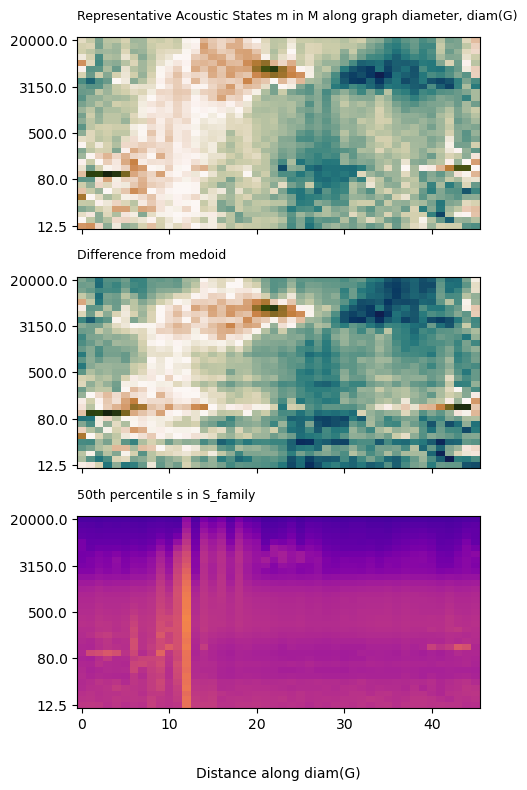

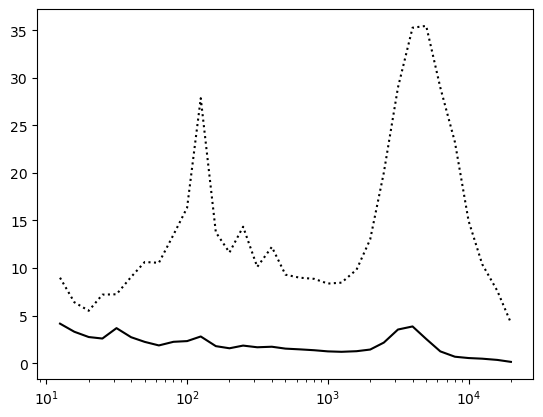

Direct spherical distance: 1.4163816996631802
MST pith distance: 24.709973440829717
ratio: 17.445843480402086
N_0 in Exposure = 1024
N_1 in Exposure = 19
N_2 in Exposure = 6
N_0 in Time = 1024
N_1 in Time = 711
N_2 in Time = 516


In [15]:
p = 50

# some basic statistics
print("Number of prototypes:", len(G))
print("Number of diameter nodes:", len(pith))
print("Number of families:", len(families))
print("Family sizes:", {k: len(v) for k, v in families.items()})
print("Unassigned prototypes:", set(G.nodes) - set(attachment))
print("Unique frame families:", S_family["pith_family"].nunique())

print(f"Achieved a {100*(1-(len(pith)/S.shape[0])) : .3f}% compression of the acoustic environment.")

diam_order = ordered_path_nodes(pith)

# Prototype/family labels for each original observation
family = S_family["pith_family"].to_numpy()

# Pth percentlie spectrum for each prototype family
S_family_p = np.full_like(X_N, np.nan, dtype=float)

for i in range(len(X_N)):
    mask = family == i

    if np.any(mask):
        S_family_p[i] = np.nanpercentile(S.loc[:,f_lower:f_upper][mask], p, axis=0)

# Reorder families according to the pith
S_diam_p = S_family_p[diam_order]

fig, ax = plt.subplots(3, 1, figsize=(5, 8), sharex=True)

ax[0].imshow(
    X_N[diam_order].T,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmocean.cm.tarn_r
)
ax[0].set_yticks(np.arange(M_df.shape[1])[::8])
ax[0].set_yticklabels(M_df.columns.astype(float)[::8], fontsize=10)
ax[0].set_title(r"Representative Acoustic States m in M along graph diameter, diam(G)", 
                loc="left", fontsize=9, y=1.05)
# ax[0].set_ylabel("Frequency band", labelpad=20)

ax[1].imshow(
    (X_N[diam_order] - X_N[medoid_idx]).T,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmocean.cm.tarn_r
)
ax[1].set_yticks(np.arange(M_df.shape[1])[::8])
ax[1].set_yticklabels(M_df.columns.astype(float)[::8], fontsize=10)
# For prototype \(i\), how much does its normalized spectral coordinate 
# in frequency band \(b\) differ from the medoid's coordinate in that same band?
ax[1].set_title(r"Difference from medoid", 
                loc="left", fontsize=9, y=1.05)

ax[2].imshow(
    S_family_p[diam_order].T,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="plasma",
    vmin=-10,
    vmax=90
)
ax[2].set_yticks(np.arange(M_df.shape[1])[::8])
ax[2].set_yticklabels(M_df.columns.astype(float)[::8], fontsize=10)
ax[2].set_title(f"{p}th percentile s in S_family",
                loc="left", fontsize=9, y=1.05)
ax[2].set_xlabel(r"Distance along diam(G)", labelpad=25, fontsize=10)
# ax[1].set_ylabel("Frequency band", labelpad=20)

# for a in ax:
#     a.spines['top'].set_visible(False)
#     a.spines['bottom'].set_visible(False)
#     a.spines['left'].set_visible(False)
#     a.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

spectral_bias = np.sum(X_N - X_N[medoid_idx], axis=1)
new_order = np.argsort(spectral_bias)

# Prototype/family labels for each original observation
family = S_family["prototype"].to_numpy()

# Median spectrum for each prototype family
S_family_pth = np.full_like(X_N, np.nan, dtype=float)
S_family_1st = np.full_like(X_N, np.nan, dtype=float)

for i in range(len(X_N)):
    mask = family == i

    if np.any(mask):
        S_family_pth[i] = np.nanpercentile(S.loc[:,f_lower:f_upper][mask], p, axis=0)
        S_family_1st[i] = np.nanpercentile(S.loc[:,f_lower:f_upper][mask], 1, axis=0)

# Reorder families according to the pith
S_prototype_pth = S_family_pth[new_order]
S_prototype_1st = S_family_1st[new_order]

prototype_L_E_pth = 10*np.log10(np.nansum(np.power(10, S_prototype_pth/10), axis=1))
prototype_L_E_1st = 10*np.log10(np.nansum(np.power(10, S_prototype_1st/10), axis=1))

plt.plot(M_df.columns.astype('float'), S_prototype_pth.var(axis=0), color="k", ls=":")
plt.plot(M_df.columns.astype('float'), S_prototype_1st.var(axis=0), color="k")
plt.xscale('log')
plt.show()

# =================================================================================

# a quick check for spherical rings
u_ = diam_order[0]
v_ = diam_order[-1]
direct = D_geo[u_, v_]
path_length = nx.path_weight(pith, diam_order, weight="geo_distance")

print("Direct spherical distance:", direct)
print("MST pith distance:", path_length)
print("ratio:", path_length / direct)

# ====================================================================================

def effective_number(mu):
    p = np.asarray(mu, dtype=float)
    p = p[p > 0]
    p = p / p.sum()
    return np.exp(-np.sum(p * np.log(p)))

def renyi_effective_number(p_i, q):
    p = np.asarray(p_i, dtype=float)
    p = p[p > 0]
    p = p / p.sum()

    if q == 1:
        # Shannon / Hill effective number
        return np.exp(-np.sum(p * np.log(p)))

    elif q == 0:
        # Number of occupied states
        return len(p)

    else:
        power_sum = np.sum(p ** q)
        return power_sum ** (1.0 / (1.0 - q))
       

band = S_family.loc[:, f_lower:f_upper].astype(float)

E_i = (10 ** (band / 10.0)).groupby(S_family["prototype"], sort=True).sum().sum(axis=1)

T_i = S_family.groupby("prototype", sort=True).size().rename("n_i")

mu_E = E_i / E_i.sum()
mu_T = T_i / T_i.sum()

N_eff_T = effective_number(mu_T)
N_eff_E = effective_number(mu_E)

mu_E_sorted = mu_E.sort_values(ascending=False)

cum_E = mu_E_sorted.cumsum()

k_E = int(np.floor(N_eff_E))
exposure_at_Neff = cum_E.iloc[k_E - 1]

# the distribution of observations among our N prototypes
# has the same Shannon entropy as a hypothetical distribution
# in which N_eff states are occupied equally
N_eff_T, N_eff_E, N_eff_T/X_N.shape[0], N_eff_E/X_N.shape[0], exposure_at_Neff

for p_i, metric_label in zip([mu_E, mu_T], ["Exposure", "Time"]):
    for q_, num_label in zip([0, 1, 2], ["N_0", "N_1", "N_2"]):
        N_q = renyi_effective_number(p_i, q_)
        print(f"{num_label} in {metric_label} = {N_q:.0f}")

pos = nx.kamada_kawai_layout(G, dim=2)

inv_E = np.log10(1/mu_E).astype('int')
node_size_E = -15*(inv_E - inv_E.max())
inv_T = np.log10(1/mu_T).astype('int')
node_size_T = -15*(inv_T - inv_T.max())

### Talk figures

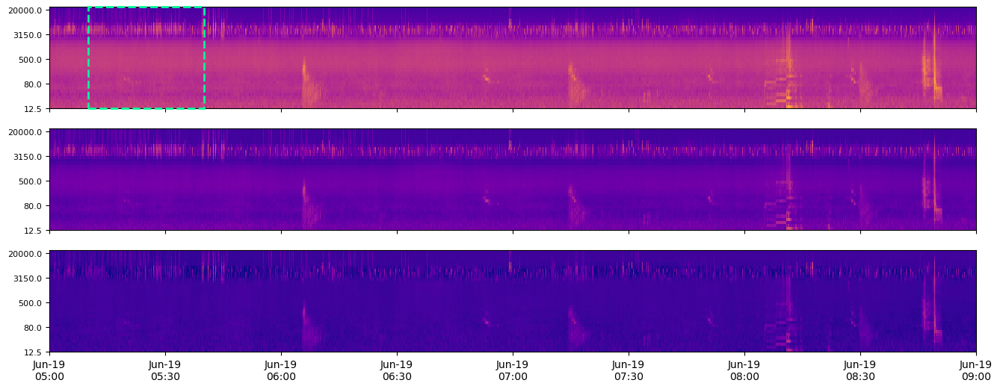

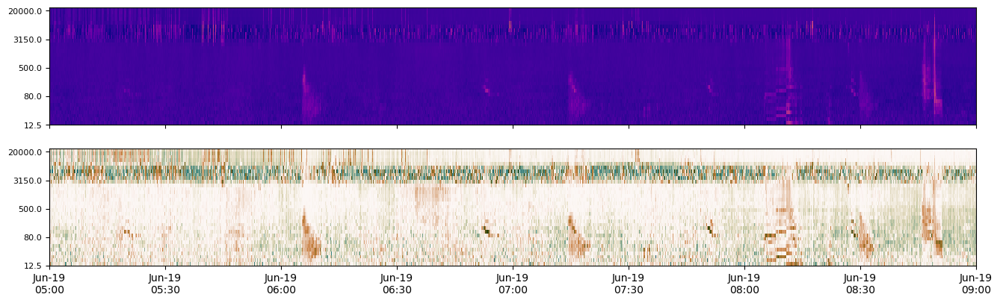

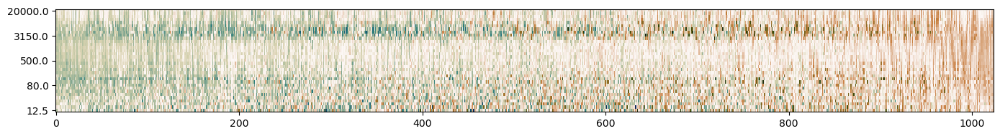

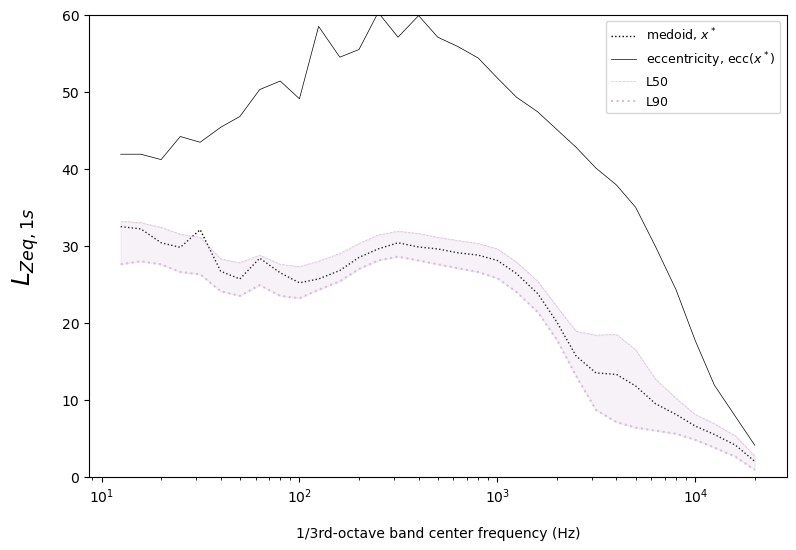

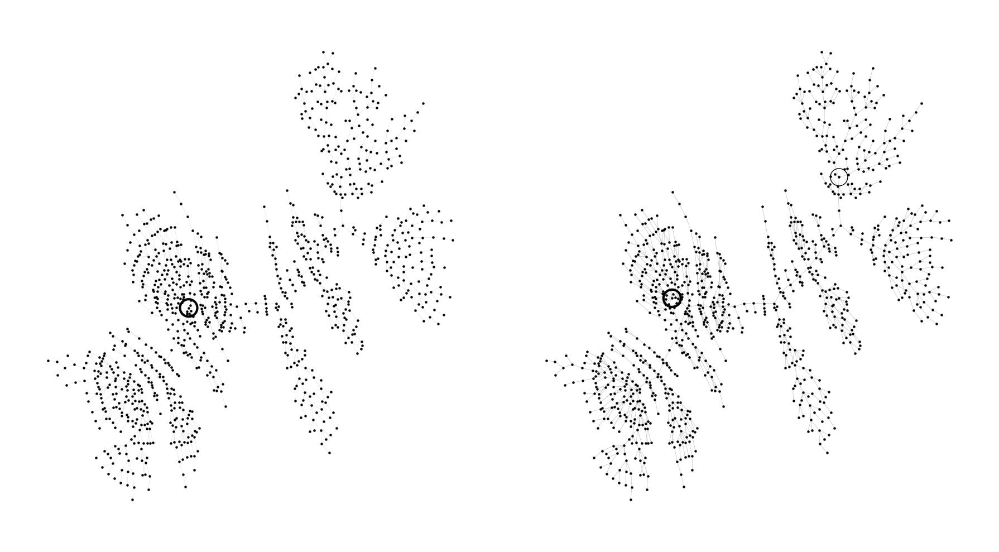

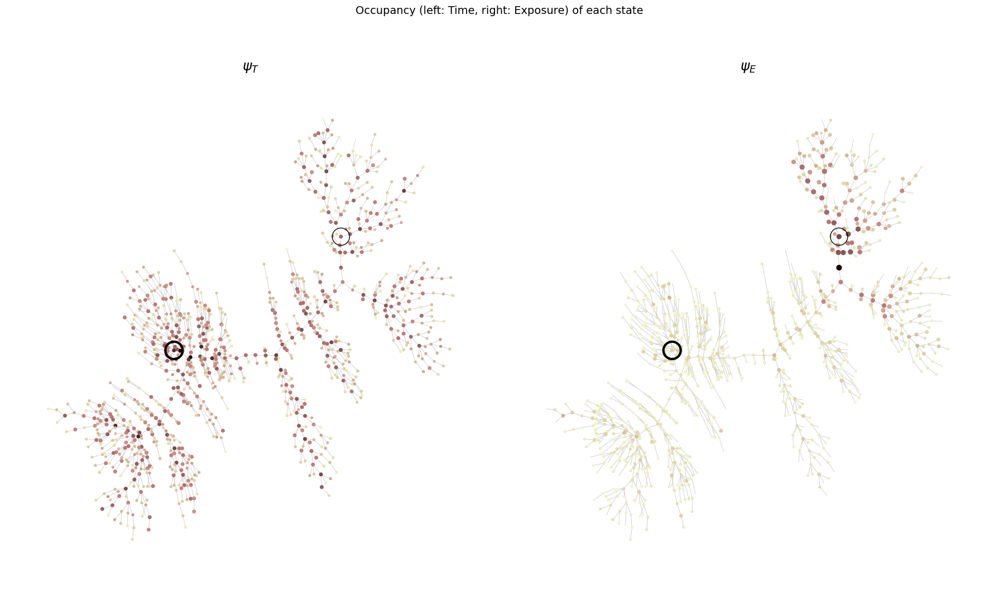

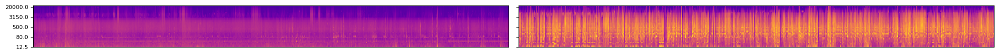

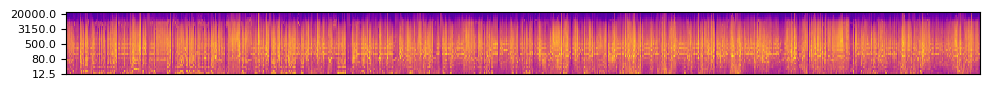

In [18]:
from matplotlib.patches import Rectangle
import datetime as dt
event_begin_ya = dt.datetime(2023,6,19,5,0,0)
event_end_ya = dt.datetime(2023,6,19,9,0,0)
shift = 10*60
epsilon_t = 30*60

#====== S → S_O → S_E ==============================================
fig,ax = plt.subplots(3,1, figsize=(16,6), sharex=True)
event_plotter(S.loc[event_begin_ya:event_end_ya], ax=ax[0])
event_plotter(S_O.loc[event_begin_ya:event_end_ya], ax=ax[1])
event_plotter(S_E.loc[event_begin_ya:event_end_ya], ax=ax[2])
p = plt.Rectangle((event_begin_ya + dt.timedelta(seconds=shift), 0), dt.timedelta(seconds=epsilon_t), 33, 
                  fill=False, lw=2, color="mediumspringgreen", ls="--", zorder=5000)
p.set_clip_on(False)
ax[0].add_patch(p)
plt.savefig(r"F:\LACLCRES_scale-selective_ambient_subtraction_example_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()

# ====== S_E → M ====================================================
fig,ax = plt.subplots(2,1, figsize=(16,4.5), sharex=True)
event_plotter(S_E.loc[event_begin_ya:event_end_ya], ax=ax[0])
event_plotter(M_df.loc[event_begin_ya:event_end_ya], ax=ax[1], 
              vmin=-1, vmax=1, cmap=cmocean.cm.tarn_r)
plt.savefig(r"F:\LACLCRES_exposure_to_hypersphere_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()



#====== M → X_N ====================================================

spectral_bias = np.sum(X_N - X_N[medoid_idx], axis=1)
spectral_bias_order = np.argsort(spectral_bias)

fig, ax = plt.subplots(1, 1, figsize=(14,2), sharex=True)

ax.imshow(
    X_N[spectral_bias_order].T,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmocean.cm.tarn_r)
ax.set_yticks(np.arange(M_df.shape[1])[::8])
ax.set_yticklabels(M_df.columns.astype(float)[::8], fontsize=10)
plt.savefig(r"F:\LACLCRES_repesentative_spectral_states_ordered_by_spectral_bias_20261110.png",
            dpi=600, bbox_inches="tight")
plt.tight_layout()
plt.show()

# ======= X_N ======================

plt.figure(figsize=(9,6))
plt.plot(f_plot, medoid_spectrum.loc[f_lower:f_upper], color="k", ls=":", lw=1, zorder=-50, label="medoid, $x^*$")
plt.plot(f_plot, medoid_contrast_spectrum.loc[f_lower:f_upper], color="k", ls="-", lw=0.5, label="eccentricity, ecc($x^*$)")
plt.plot(f_plot, L50.loc[f_lower:f_upper].values, color="thistle", ls="--", lw=0.5, zorder=100, label="L50")
plt.plot(f_plot, L90.loc[f_lower:f_upper].values, color="thistle", ls=":", zorder=100, label="L90")
plt.fill_between(f_plot, L90.loc[f_lower:f_upper].values, L50.loc[f_lower:f_upper].values, color="thistle", alpha=0.2)
plt.legend(fontsize=9)
plt.xscale('log')
plt.ylim([0,60])
plt.xlabel("1/3rd-octave band center frequency (Hz)", labelpad=15)
plt.ylabel("$L_{Zeq,1s}$", fontsize=18, labelpad=15)
plt.savefig(r"F:\LACLCRES_backtransform_to_S_medoid_and_ecc_L50_L90_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()
plt.close()

# ========= X_N → G_MST ============================

# pos = nx.kamada_kawai_layout(G, dim=2)

fig,ax = plt.subplots(1,2, figsize=(18,8))
nx.draw(G, pos, node_size=5, 
        node_color="k", 
        width=0.2, edge_color="silver", ax=ax[0])
nx.draw_networkx_nodes(G, pos, nodelist=[m_pith_node], node_size=500, node_color="none", edgecolors="k", linewidths=3, ax=ax[0])
nx.draw(G, pos, node_size=5, 
        node_color="k", 
        width=0.5, edge_color="silver", ax=ax[1])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_idx], node_size=500, node_color="none", edgecolors="k", linewidths=3, ax=ax[1])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_contrast_idx], node_size=500, node_color="none", edgecolors="k", linewidths=1, ax=ax[1])
# fig.suptitle("Occupancy (left: Time, right: Exposure) of each state", y=1.05, fontsize=14)
# ax[1].set_title(r"$\psi_E$", fontsize=18)
# ax[0].set_title(r"$\psi_T$", fontsize=18)
plt.tight_layout()
plt.savefig(r"F:\LACLCRES_X_N_to_G_MST_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()

# # ========= G_MST → Pi ============================

inv_E = np.log10(1/mu_E).astype('int')
node_size_E = -8*(inv_E - inv_E.max())
inv_T = np.log10(1/mu_T).astype('int')
node_size_T = -8*(inv_T - inv_T.max())

fig,ax = plt.subplots(1,2, figsize=(18,8))
nx.draw(G, pos, node_size=node_size_E.iloc[list(G.nodes)], 
        node_color=np.log(mu_E.iloc[list(G.nodes)]), cmap="pink_r", 
        width=0.5, edge_color="silver", ax=ax[1])
nx.draw(G, pos, node_size=node_size_T.iloc[list(G.nodes)], 
        node_color=np.log(mu_T.iloc[list(G.nodes)]), cmap="pink_r", 
        width=0.5, edge_color="silver", ax=ax[0])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_idx], node_size=500, node_color="none", edgecolors="k", linewidths=3, ax=ax[0])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_contrast_idx], node_size=500, node_color="none", edgecolors="k", linewidths=1, ax=ax[0])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_idx], node_size=500, node_color="none", edgecolors="k", linewidths=3, ax=ax[1])
nx.draw_networkx_nodes(G, pos, nodelist=[medoid_contrast_idx], node_size=500, node_color="none", edgecolors="k", linewidths=1, ax=ax[1])
fig.suptitle("Occupancy (left: Time, right: Exposure) of each state", y=1.05, fontsize=14)
ax[1].set_title(r"$\psi_E$", fontsize=18)
ax[0].set_title(r"$\psi_T$", fontsize=18)
plt.tight_layout()
plt.savefig(r"F:\LACLCRES_G_MST_with_partition_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()

# =========== 

S_medoid = S_family.loc[S_family["prototype"].isin([medoid_idx]), "12.5":"20000"]
S_ecc = S_family.loc[S_family["prototype"].isin([medoid_contrast_idx]), "12.5":"20000"]

fig,ax = plt.subplots(1,2, figsize=(20,1.2), sharey=True)
event_plotter(S_medoid, ax=ax[0])
event_plotter(S_ecc, ax=ax[1])
plt.xticks([], [])
for a in ax:
    a.set_xticks([])
    a.set_xticks([], minor=True)
plt.tight_layout()
plt.savefig(r"F:\LACLCRES_S_medoid_and_ecc_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()
plt.close()

fig,ax = plt.subplots(1,1, figsize=(10,1), sharex=True)
event_plotter(S_ecc, ax=ax)
plt.xticks([], [])
ax.set_xticks([])
ax.set_xticks([], minor=True)
plt.tight_layout()
plt.savefig(r"F:\LACLCRES_S_ecc_20261110.png",
            dpi=600, bbox_inches="tight")
plt.show()
plt.close()

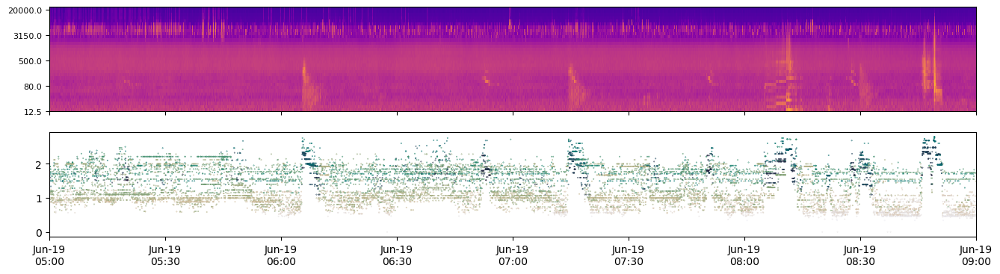

In [229]:
thetas = pd.Series(angular_separation_from_medoid(X_N, X_N[medoid_idx]), index=np.arange(len(X_N)))
angle_theta = thetas.loc[S_family["prototype"]]
angle_theta.index = S_family.index

S_family["d_medoid"] = angle_theta
S_family["spectral_bias"] = spectral_bias[S_family["prototype"]]

ka = nx.eigenvector_centrality_numpy(G, max_iter=5000)
# ka = nx.information_centrality(G)
# ka = nx.subgraph_centrality(G)
# ka = nx.harmonic_centrality(G)
# ka = nx.laplacian_centrality(G)
S_family["eigen_centrality"] = S_family["prototype"].map(ka)

fig,ax = plt.subplots(2,1, figsize=(16,4), sharex=True)
event_plotter(S.loc[event_begin_ya:event_end_ya], ax=ax[0])
ax[1].scatter(S_family.loc[event_begin_ya:event_end_ya, :].index, 
           S_family.loc[event_begin_ya:event_end_ya, "d_medoid"], 
              c=np.log(S_family.loc[event_begin_ya:event_end_ya, "eigen_centrality"]), 
              cmap=cmocean.cm.rain_r, s=0.1)
# p = plt.Rectangle((event_begin_ya + dt.timedelta(seconds=shift), 0), dt.timedelta(seconds=epsilon_t), 33, 
# #                   fill=False, lw=2, color="mediumspringgreen", ls="--", zorder=5000)
# p.set_clip_on(False)
# # ax[0].add_patch(p)
# plt.savefig(r"F:\LACLCRES_scale-selective_ambient_subtraction_example_20261110.png",
#             dpi=600, bbox_inches="tight")
plt.show()

#### Comparison to `SPLAT`-based partition

In [17]:
src_obj = Srcid([e.path for e in archive.srcid(unit=u, site=s, year=y)][0])
src = src_obj.data

boolean_sum = binary_audibility_time_series(src=src, resolution='1s')

nv_aud = join_src_to_nvspl(nv, src)

S_family_aud = S_family.join(nv_aud["Audible"])
S_medoid_set = S_family_aud.loc[S_family_aud["prototype"].isin([medoid_idx]),:]
S_medoid_contrast = S_family_aud.loc[S_family_aud["prototype"].isin([medoid_contrast_idx]),:]

TA_medoid = S_medoid_set["Audible"].sum()/S_medoid_set.shape[0]
TA_medoid_contrast = S_medoid_contrast["Audible"].sum()/S_medoid_contrast.shape[0]
TA_overall = np.nansum(S_family_aud["Audible"])/S_family_aud.shape[0]

# print(f"Overall TA: {100*TA_overall : .1f}%, Medoid TA: {100*TA_medoid : .1f}%, Medoid-contrast TA: {100*TA_medoid_contrast : .1f}%")
# print(f"Overall relative concentration: {TA_medoid_contrast/TA_overall : .1f}x, {TA_medoid_contrast/TA_medoid : .1f}x")

SIR_medoid = audibility_sir(S_medoid_set, TA_overall)
SIR_contrast = audibility_sir(S_medoid_contrast, TA_overall)

print(f"Overall TA: {100*TA_overall:.1f}%, "
      f"Medoid TA: {100*TA_medoid:.1f}%, "
      f"Medoid-contrast TA: {100*TA_medoid_contrast:.1f}%")

print(f"Medoid SIR: {SIR_medoid:.1f}, "
      f"Medoid-contrast SIR: {SIR_contrast:.1f}")

C:\Users\DBetchkal\AppData\Local\Temp\21\ipykernel_9624\2399771778.py:40: ChainedAssignmentError: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
When using the Copy-on-Write mode, such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object.


  nv_aud["Audible"].fillna(0, inplace=True)


Overall TA: 27.1%, Medoid TA: 19.9%, Medoid-contrast TA: 96.4%
Medoid SIR: 0.7, Medoid-contrast SIR: 3.6


In [76]:
def binary_audibility_time_series(src, resolution='1S'):

    '''
    

    Parameters
    ----------

    src: 
    resolution:  

    Returns
    -------
    '''

    I_n = src.index + src.len # our noise intervals: the index and the series
    
    start_time = I_n.index.min() # the index of `I_n` is the time audibility begins
    end_time = I_n.max() # the 
    
    # Generate a time range with the desired resolution (e.g., 'T' for minute, 'S' for second)
    time_index = pd.date_range(start=start_time, end=end_time, freq=resolution)
    
    # Initialize a binary series with zeros
    binary_series = pd.Series(0, index=time_index, name="Audible")
    
    # Loop through each interval and set presence to 1 in the binary series
    for start, end in zip(I_n.index, I_n.values):
        binary_series.loc[start:end] = 1

    return binary_series

def join_src_to_nvspl(nv, src):
    '''
    '''

    boolean_sum = binary_audibility_time_series(src, resolution='1s')

    nv_aud = nv.join(boolean_sum, how="outer")
    nv_aud["Audible"].fillna(0, inplace=True)

    return nv_aud

def audibility_sir(family, overall_ta):
    """
    Standardized Incidence Ratio (SIR) for audible spectra
    within a RAS family.

    SIR = observed audible spectra /
          expected audible spectra under the overall rate.
    """
    n = family.shape[0]
    observed = family["Audible"].sum()
    expected = n * overall_ta

    return observed / expected if expected > 0 else np.nan


src_obj = Srcid([e.path for e in archive.srcid(unit=u, site=s, year=y)][0])
src = src_obj.data

boolean_sum = binary_audibility_time_series(src=src, resolution='1S')

nv_aud = join_src_to_nvspl(nv, src)

S_family_aud = S_family.join(nv_aud["Audible"])
S_medoid_set = S_family_aud.loc[S_family_aud["prototype"].isin([medoid_idx]),:]
S_medoid_contrast = S_family_aud.loc[S_family_aud["prototype"].isin([medoid_contrast_idx]),:]

TA_medoid = S_medoid_set["Audible"].sum()/S_medoid_set.shape[0]
TA_medoid_contrast = S_medoid_contrast["Audible"].sum()/S_medoid_contrast.shape[0]
TA_overall = np.nansum(S_family_aud["Audible"])/S_family_aud.shape[0]

# print(f"Overall TA: {100*TA_overall : .1f}%, Medoid TA: {100*TA_medoid : .1f}%, Medoid-contrast TA: {100*TA_medoid_contrast : .1f}%")
# print(f"Overall relative concentration: {TA_medoid_contrast/TA_overall : .1f}x, {TA_medoid_contrast/TA_medoid : .1f}x")

SIR_medoid = audibility_sir(S_medoid_set, TA_overall)
SIR_contrast = audibility_sir(S_medoid_contrast, TA_overall)

print(f"Overall TA: {100*TA_overall:.1f}%, "
      f"Medoid TA: {100*TA_medoid:.1f}%, "
      f"Medoid-contrast TA: {100*TA_medoid_contrast:.1f}%")

print(f"Medoid SIR: {SIR_medoid:.1f}, "
      f"Medoid-contrast SIR: {SIR_contrast:.1f}")

C:\Users\DBetchkal\AppData\Local\Temp\20\ipykernel_18756\42503449.py:22: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq=resolution)
C:\Users\DBetchkal\AppData\Local\Temp\20\ipykernel_18756\42503449.py:40: ChainedAssignmentError: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
When using the Copy-on-Write mode, such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object.


  nv_aud["Audible"].fillna(0, inplace=True)


Overall TA: 27.1%, Medoid TA: 27.3%, Medoid-contrast TA: 96.1%
Medoid SIR: 1.0, Medoid-contrast SIR: 3.5


#### A well-vetted (new) measure of information-weighted velocity, $v_H$

In [89]:
def hypersphere_velocity_weighted(arr):
    """
    Compute hypersphere-aware velocity:
    v_t = -log p(theta_t), where p(theta) ~ sin(theta)^(d-2)

    Returns information-weighted velocity.
    """

    M = arr.values.astype(float)

    # normalize
    norms = np.linalg.norm(M, axis=1, keepdims=True) + 1e-12
    M = M / norms

    # dot products
    dots = np.sum(M[1:] * M[:-1], axis=1)
    dots = np.clip(dots, -1.0, 1.0)

    theta = np.arccos(dots)

    d = M.shape[1]

    log_p = (d - 2) * np.log(np.sin(theta) + 1e-12)
    v = -log_p

    v = np.insert(v, 0, np.nan)
    v_out = pd.Series(v, index=arr.index)
    theta = np.insert(theta, 0, np.nan)
    theta_out = pd.Series(theta, index=arr.index)

    return v_out, theta_out

v_H, _ = hypersphere_velocity_weighted(M_df)
S_family["v_H"] = v_H

#### Usefully, visualize the partition associated with each state...

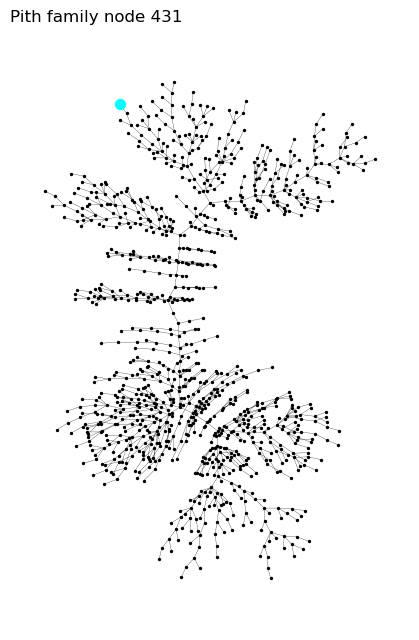

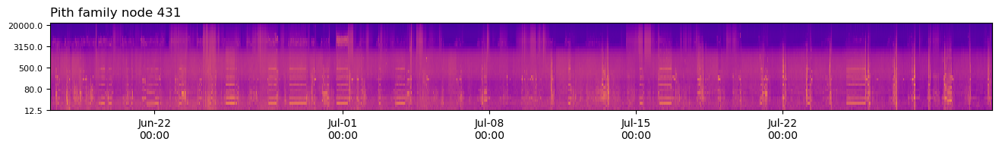

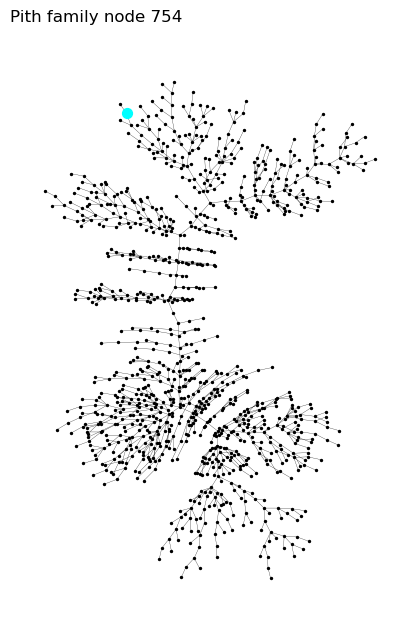

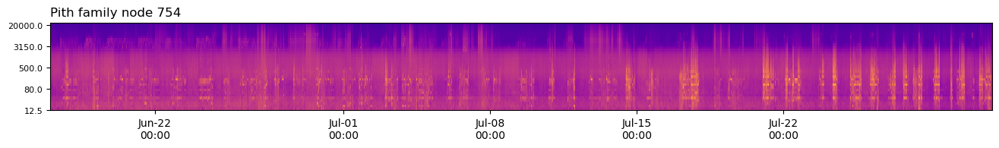

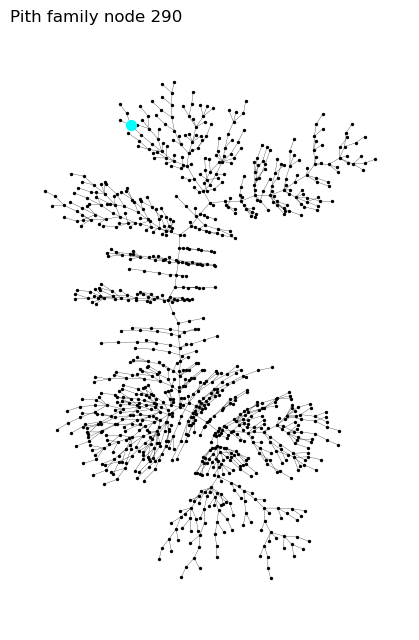

...

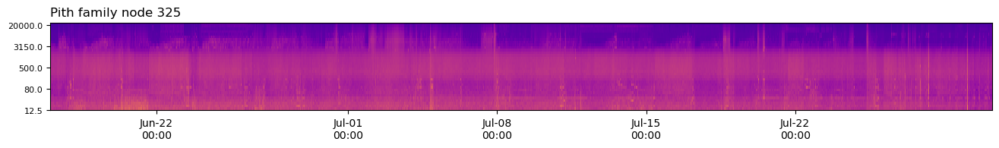

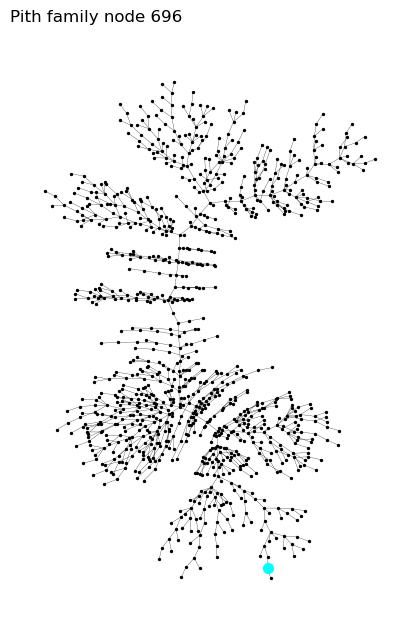

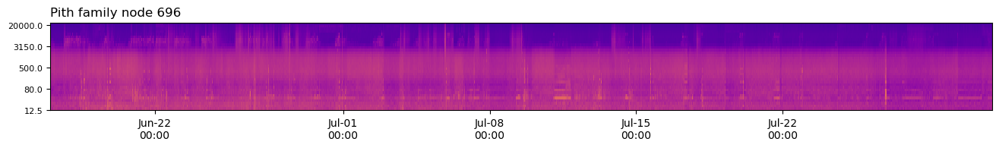

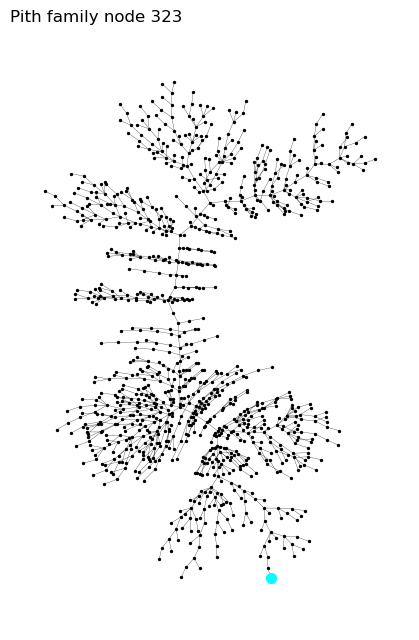

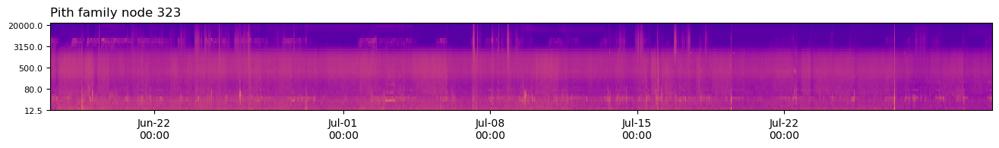

In [75]:
order_occ = np.argsort(occupancy_heatmap[0])
# pos = nx.kamada_kawai_layout(G, dim=2)

color_by_dynamics = np.log(dynamics.iloc[list(G.nodes), :]["n_visits"])

for node_sel in order_sheesh:

    plt.figure(figsize=(4, 6))
    nx.draw(G, pos, node_size=2, node_color="k", width=0.2)
    # nx.draw_networkx_edges(pith, pos, width=0.2, color=")
    # nx.draw_networkx_nodes(G, pos, node_size=node_size)
    nx.draw_networkx_nodes(G, pos, nodelist=[node_sel], node_size=50, node_color="cyan") # or, 113
    # nx.draw_networkx_nodes(G, pos, nodelist=[m_pith_node], node_size=10, node_color="magenta")
    # nx.draw_networkx_nodes(G, pos, nodelist=[medoid_idx], node_size=100, node_color="none", edgecolors="magenta", linewidths=1.5)
    # nx.draw_networkx_nodes(G, pos, nodelist=[medoid_idx], node_size=100, node_color="none", edgecolors="magenta", linewidths=1.5)
    # plt.savefig("/home/waxy/Desktop/spectral_layout.png",
    #             dpi=72, bbox_inches="tight", facecolor="white")
    plt.title(f"Pith family node {node_sel}", loc="left")
    plt.show()
    
    fig,ax = plt.subplots(1,1, figsize=(16,1.5))
    ax.set_title(f"Pith family node {node_sel}", loc="left")
    event_plotter(S_family.loc[S_family["pith_family"] == node_sel, "12.5":"20000"], ax=ax)
    plt.show()
    plt.close()